In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Sales Prediction Project Started!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Sales Prediction Project Started!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [2]:


import pandas as pd

url = "https://raw.githubusercontent.com/nguyen-toan/ISLR/master/dataset/Advertising.csv"

df = pd.read_csv(url)

# Display the first 5 rows
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Get basic statistical information
print("\nStatistical summary:")
df.describe()

Dataset shape: (200, 5)

Column names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Statistical summary:


,Unnamed: 0,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,147.042500,23.264000,30.554000,14.022500
std,57.879185,85.854236,14.846809,21.778621,5.217457
min,1.000000,0.700000,0.000000,0.300000,1.600000
25%,50.750000,74.375000,9.975000,12.750000,10.375000
50%,100.500000,149.750000,22.900000,25.750000,12.900000
75%,150.250000,218.825000,36.525000,45.100000,17.400000
max,200.000000,296.400000,49.600000,114.000000,27.000000


In [4]:


# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check data types
print("\nData types:")
print(df.dtypes)

# 4. Check for negative values
print("\nNegative values in each column:")
print((df.select_dtypes(include="number") < 0).sum())

Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate rows: 0

Data types:
Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

Negative values in each column:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64


In [5]:


df = df.drop(columns=["Unnamed: 0"])

print("Updated dataset shape:", df.shape)
print("\nFinal columns:", df.columns.tolist())

df.head()

Updated dataset shape: (200, 4)

Final columns: ['TV', 'Radio', 'Newspaper', 'Sales']


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


Correlation with Sales:
Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


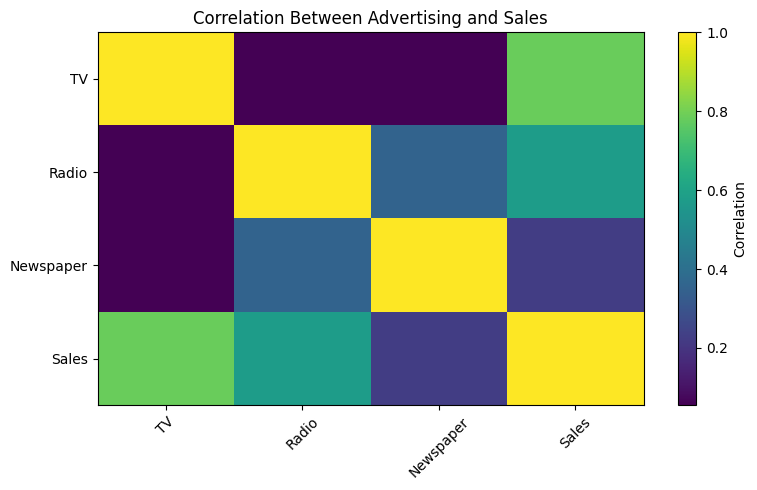

In [6]:


# Calculate correlations
correlation = df.corr(numeric_only=True)

print("Correlation with Sales:")
print(correlation["Sales"].sort_values(ascending=False))

# Visualize the correlation matrix
plt.figure(figsize=(8, 5))

plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(range(len(correlation.columns)), correlation.columns,
           rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.show()

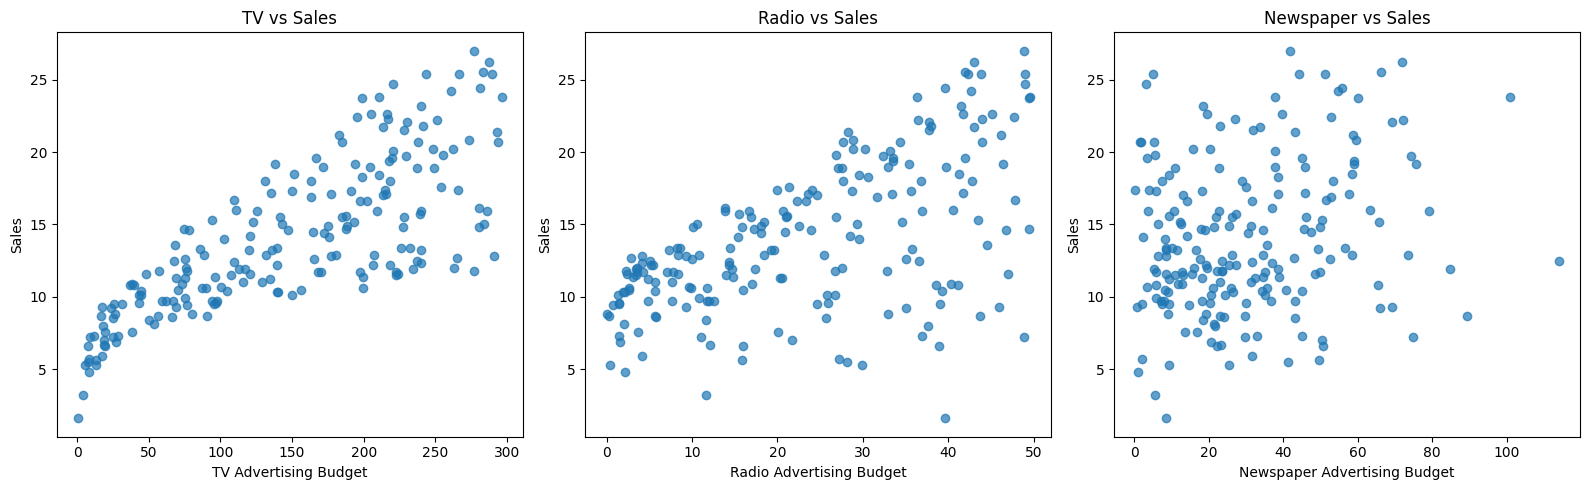

In [7]:


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

features = ["TV", "Radio", "Newspaper"]

for ax, feature in zip(axes, features):
    ax.scatter(df[feature], df["Sales"], alpha=0.7)
    ax.set_xlabel(f"{feature} Advertising Budget")
    ax.set_ylabel("Sales")
    ax.set_title(f"{feature} vs Sales")

plt.tight_layout()
plt.show()

In [8]:


X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Check the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (160, 3)
Testing features: (40, 3)
Training target: (160,)
Testing target: (40,)


In [9]:


from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [10]:
# Display the learned coefficients

print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature} coefficient: {coefficient:.4f}")

Intercept: 2.979067338122629
TV coefficient: 0.0447
Radio coefficient: 0.1892
Newspaper coefficient: 0.0028


In [11]:


y_pred = model.predict(X_test)

# Compare actual and predicted sales
results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

results["Error"] = (
    results["Actual Sales"] - results["Predicted Sales"]
)

print(results.head(10).round(2))

   Actual Sales  Predicted Sales  Error
0          16.9            16.41   0.49
1          22.4            20.89   1.51
2          21.4            21.55  -0.15
3           7.3            10.61  -3.31
4          24.7            22.11   2.59
5          12.6            13.11  -0.51
6          22.3            21.06   1.24
7           8.4             7.46   0.94
8          11.5            13.61  -2.11
9          14.9            15.16  -0.26


In [12]:


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("------------------")
print(f"MAE  : {mae:.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.4f}")

MODEL PERFORMANCE
------------------
MAE  : 1.461
MSE  : 3.174
RMSE : 1.782
R²   : 0.8994


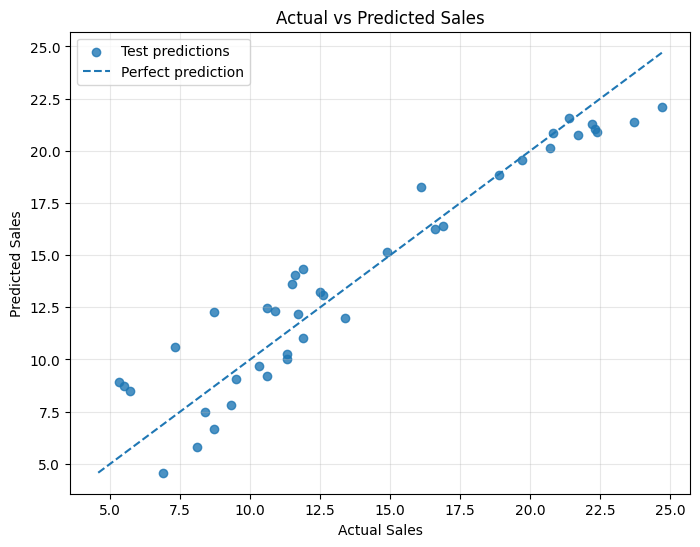

In [13]:


plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.8, label="Test predictions")

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:


new_campaign = pd.DataFrame({
    "TV": [150.0],
    "Radio": [25.0],
    "Newspaper": [20.0]
})

predicted_sales = model.predict(new_campaign)[0]

print("NEW CAMPAIGN")
print("------------")
print("TV budget:", new_campaign.loc[0, "TV"])
print("Radio budget:", new_campaign.loc[0, "Radio"])
print("Newspaper budget:", new_campaign.loc[0, "Newspaper"])

print(f"\nPredicted sales: {predicted_sales:.2f}")

NEW CAMPAIGN
------------
TV budget: 150.0
Radio budget: 25.0
Newspaper budget: 20.0

Predicted sales: 14.47


Mean residual: -0.098
Minimum residual: -3.603
Maximum residual: 2.588


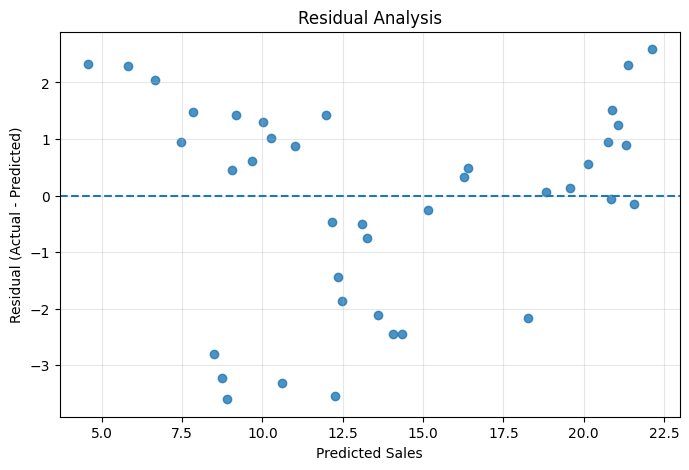

In [15]:


residuals = y_test.to_numpy() - y_pred

print("Mean residual:", round(residuals.mean(), 3))
print("Minimum residual:", round(residuals.min(), 3))
print("Maximum residual:", round(residuals.max(), 3))

# Plot residuals against predicted sales
plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.8)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis")
plt.grid(alpha=0.3)
plt.show()

In [16]:


from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline model: always predicts average training sales
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Generate predictions from both models
baseline_pred = baseline.predict(X_test)
linear_pred = model.predict(X_test)

# Compare performance
comparison = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_pred),
        mean_absolute_error(y_test, linear_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        np.sqrt(mean_squared_error(y_test, linear_pred))
    ],
    "R2": [
        r2_score(y_test, baseline_pred),
        r2_score(y_test, linear_pred)
    ]
})

print(comparison.round(4))

               Model     MAE    RMSE      R2
0           Baseline  4.9625  5.6315 -0.0048
1  Linear Regression  1.4608  1.7816  0.8994


In [17]:


from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
import numpy as np

# Define the cross-validation strategy
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Linear Regression across five folds
cv_results = cross_validate(
    LinearRegression(),
    X,
    y,
    cv=kfold,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    }
)

# Convert negative error scores into positive values
print("Five-fold cross-validation results")
print("----------------------------------")

print("R² scores:", np.round(cv_results["test_r2"], 4))
print("MAE scores:", np.round(-cv_results["test_mae"], 4))
print("RMSE scores:", np.round(-cv_results["test_rmse"], 4))

print("\nAverage R²:", round(cv_results["test_r2"].mean(), 4))
print("Average MAE:", round(-cv_results["test_mae"].mean(), 4))
print("Average RMSE:", round(-cv_results["test_rmse"].mean(), 4))

Five-fold cross-validation results
----------------------------------
R² scores: [0.8994 0.819  0.934  0.901  0.8603]
MAE scores: [1.4608 1.3249 1.0295 1.2963 1.3249]
RMSE scores: [1.7816 1.8149 1.2739 1.6822 1.9761]

Average R²: 0.8827
Average MAE: 1.2873
Average RMSE: 1.7057


In [18]:


import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# Define the models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

# Use the same folds for every model
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

comparison = []

for name, estimator in models.items():

    scores = cross_validate(
        estimator,
        X,
        y,
        cv=kfold,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        }
    )

    comparison.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

            Model  Mean R2  Mean MAE  Mean RMSE
Linear Regression   0.8827    1.2873     1.7057
 Ridge Regression   0.8827    1.2873     1.7057
    Random Forest   0.9808    0.5398     0.7035


In [19]:


from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

train_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=train_cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        }
    )

    rows.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

training_comparison = pd.DataFrame(rows)
print(training_comparison.round(4).to_string(index=False))

            Model  Mean R2  Mean MAE  Mean RMSE
Linear Regression   0.8703    1.2371     1.6758
 Ridge Regression   0.8703    1.2371     1.6758
    Random Forest   0.9662    0.6417     0.8932


In [20]:
# Train Random Forest on the training data
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict the original test records
rf_pred = rf_model.predict(X_test)

print("Random Forest Test Performance")
print("--------------------------------")
print(f"MAE:  {mean_absolute_error(y_test, rf_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, rf_pred)):.4f}")
print(f"R2:   {r2_score(y_test, rf_pred):.4f}")

Random Forest Test Performance
--------------------------------
MAE:  0.6287
RMSE: 0.7572
R2:   0.9818


In [21]:


import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "sales_prediction_model.pkl")

print("Model saved successfully!")

# Load the saved model
loaded_model = joblib.load("sales_prediction_model.pkl")

# Test that the saved model works
sample_campaign = pd.DataFrame({
    "TV": [150.0],
    "Radio": [25.0],
    "Newspaper": [20.0]
})

prediction = loaded_model.predict(sample_campaign)[0]

print(f"Predicted sales: {prediction:.2f}")

Model saved successfully!
Predicted sales: 15.16


In [22]:
%pip install -q gradio

In [23]:
import gradio as gr
import pandas as pd

def predict_sales(tv, radio, newspaper):
    # Prepare the inputs in the format expected by the model
    campaign = pd.DataFrame({
        "TV": [tv],
        "Radio": [radio],
        "Newspaper": [newspaper]
    })

    # Predict sales using our saved model
    prediction = loaded_model.predict(campaign)[0]

    return round(float(prediction), 2)


demo = gr.Interface(
    fn=predict_sales,
    inputs=[
        gr.Number(label="TV Advertising Budget", value=150),
        gr.Number(label="Radio Advertising Budget", value=25),
        gr.Number(label="Newspaper Advertising Budget", value=20)
    ],
    outputs=gr.Number(label="Predicted Sales"),
    title="Sales Prediction System",
    description="Enter advertising budgets to estimate sales using our trained Random Forest model."
)

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [24]:
import sqlite3

# Connect to the database (creates the file if it doesn't exist)
conn = sqlite3.connect("sales_predictions.db")
cursor = conn.cursor()

# Create a table to store prediction history
cursor.execute("""
CREATE TABLE IF NOT EXISTS prediction_history (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    tv_budget REAL NOT NULL,
    radio_budget REAL NOT NULL,
    newspaper_budget REAL NOT NULL,
    predicted_sales REAL NOT NULL,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
)
""")

conn.commit()

print("Database and table created successfully!")

Database and table created successfully!


In [25]:
cursor.execute("""
INSERT INTO prediction_history
(tv_budget, radio_budget, newspaper_budget, predicted_sales)
VALUES (?, ?, ?, ?)
""", (150.0, 25.0, 20.0, 15.16))

conn.commit()

print("Prediction saved successfully!")

Prediction saved successfully!


In [26]:
cursor.execute("""
SELECT *
FROM prediction_history
ORDER BY created_at DESC
""")

rows = cursor.fetchall()

for row in rows:
    print(row)

(1, 150.0, 25.0, 20.0, 15.16, '2026-10-16 08:39:05')


In [27]:

import gradio as gr
import pandas as pd
import sqlite3

def predict_sales(tv, radio, newspaper):
    # Validate the input
    if tv is None or radio is None or newspaper is None:
        raise gr.Error("Please enter all three advertising budgets.")

    if tv < 0 or radio < 0 or newspaper < 0:
        raise gr.Error("Advertising budgets cannot be negative.")

    # Prepare input for the ML model
    campaign = pd.DataFrame({
        "TV": [tv],
        "Radio": [radio],
        "Newspaper": [newspaper]
    })

    # Predict sales
    prediction = float(loaded_model.predict(campaign)[0])
    prediction = round(prediction, 2)

    # Save the prediction in SQL database
    with sqlite3.connect("sales_predictions.db") as conn:
        conn.execute("""
            INSERT INTO prediction_history
            (tv_budget, radio_budget, newspaper_budget, predicted_sales)
            VALUES (?, ?, ?, ?)
        """, (tv, radio, newspaper, prediction))

    return prediction

demo = gr.Interface(
    fn=predict_sales,
    inputs=[
        gr.Number(label="TV Advertising Budget", value=150),
        gr.Number(label="Radio Advertising Budget", value=25),
        gr.Number(label="Newspaper Advertising Budget", value=20)
    ],
    outputs=gr.Number(label="Predicted Sales"),
    title="Sales Prediction System",
    description="Predict sales and automatically save each prediction to the SQL database."
)

demo.launch(share=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [28]:
with sqlite3.connect("sales_predictions.db") as conn:
    history = pd.read_sql_query("""
        SELECT *
        FROM prediction_history
        ORDER BY id DESC
    """, conn)

display(history)

,id,tv_budget,radio_budget,newspaper_budget,predicted_sales,created_at
0,2,150.0,25.0,20.0,15.16,2026-10-16 08:40:13
1,1,150.0,25.0,20.0,15.16,2026-10-16 08:39:05


In [29]:

import sqlite3
import pandas as pd

with sqlite3.connect("sales_predictions.db") as conn:
    summary = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_campaigns,
            ROUND(AVG(predicted_sales), 2) AS average_predicted_sales,
            ROUND(MAX(predicted_sales), 2) AS highest_predicted_sales,
            ROUND(MIN(predicted_sales), 2) AS lowest_predicted_sales
        FROM prediction_history
    """, conn)

display(summary)


,total_campaigns,average_predicted_sales,highest_predicted_sales,lowest_predicted_sales
0,2,15.16,15.16,15.16


In [30]:

with sqlite3.connect("sales_predictions.db") as conn:
    campaign_report = pd.read_sql_query("""
        SELECT
            id AS campaign_id,
            tv_budget,
            radio_budget,
            newspaper_budget,
            predicted_sales,
            created_at
        FROM prediction_history
        ORDER BY predicted_sales DESC
    """, conn)

display(campaign_report)


,campaign_id,tv_budget,radio_budget,newspaper_budget,predicted_sales,created_at
0,1,150.0,25.0,20.0,15.16,2026-10-16 08:39:05
1,2,150.0,25.0,20.0,15.16,2026-10-16 08:40:13


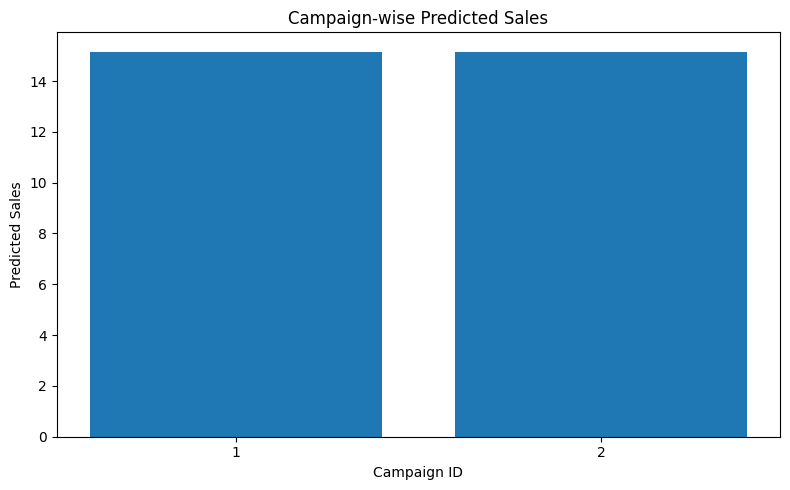

In [31]:

import matplotlib.pyplot as plt
import sqlite3
import pandas as pd

# Fetch campaign data from SQL
with sqlite3.connect("sales_predictions.db") as conn:
    campaign_data = pd.read_sql_query("""
        SELECT
            id,
            tv_budget,
            radio_budget,
            newspaper_budget,
            predicted_sales
        FROM prediction_history
        ORDER BY id
    """, conn)

# Plot predicted sales for each campaign
plt.figure(figsize=(8, 5))

plt.bar(
    campaign_data["id"].astype(str),
    campaign_data["predicted_sales"]
)

plt.xlabel("Campaign ID")
plt.ylabel("Predicted Sales")
plt.title("Campaign-wise Predicted Sales")
plt.tight_layout()
plt.show()


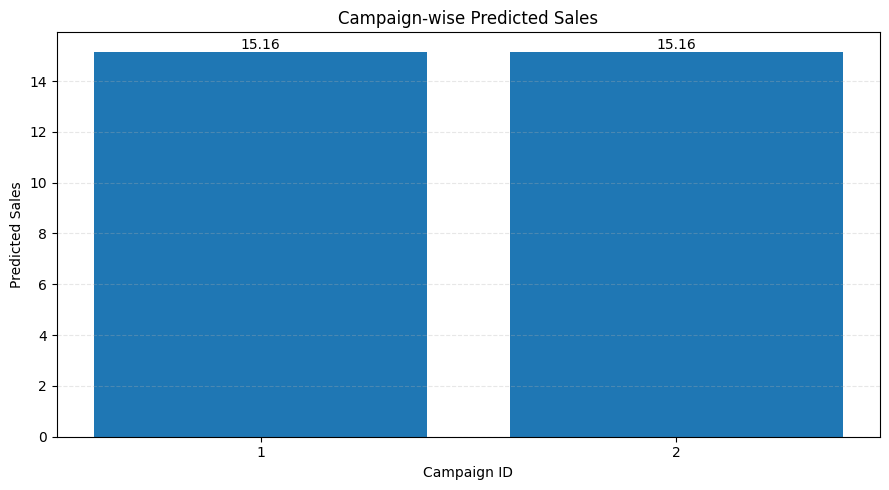

In [32]:

import matplotlib.pyplot as plt
import sqlite3
import pandas as pd

with sqlite3.connect("sales_predictions.db") as conn:
    campaign_data = pd.read_sql_query("""
        SELECT id, predicted_sales
        FROM prediction_history
        ORDER BY id
    """, conn)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    campaign_data["id"].astype(str),
    campaign_data["predicted_sales"]
)

# Display prediction values above each bar
for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.xlabel("Campaign ID")
plt.ylabel("Predicted Sales")
plt.title("Campaign-wise Predicted Sales")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [33]:
import sqlite3
import pandas as pd

with sqlite3.connect("sales_predictions.db") as conn:
    history = pd.read_sql_query("""
        SELECT *
        FROM prediction_history
        ORDER BY id DESC
    """, conn)

display(history)

,id,tv_budget,radio_budget,newspaper_budget,predicted_sales,created_at
0,3,200.0,40.0,10.0,20.32,2026-10-16 08:44:39
1,2,150.0,25.0,20.0,15.16,2026-10-16 08:40:13
2,1,150.0,25.0,20.0,15.16,2026-10-16 08:39:05


,id,tv_budget,radio_budget,newspaper_budget,predicted_sales,created_at
0,1,150.0,25.0,20.0,15.16,2026-10-16 08:39:05
1,2,150.0,25.0,20.0,15.16,2026-10-16 08:40:13
2,3,200.0,40.0,10.0,20.32,2026-10-16 08:44:39


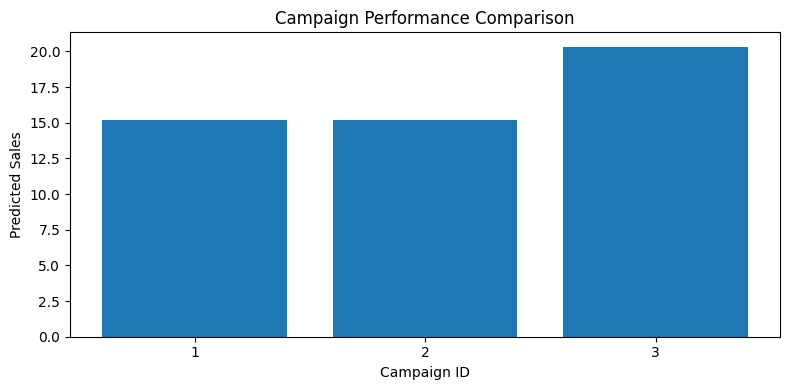

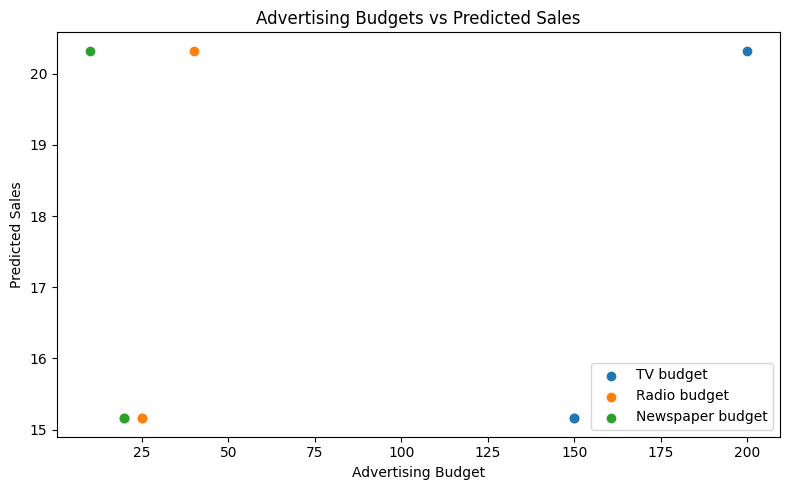

In [34]:

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Load campaign history from SQL
with sqlite3.connect("sales_predictions.db") as conn:
    campaigns = pd.read_sql_query("""
        SELECT *
        FROM prediction_history
        ORDER BY id
    """, conn)

# Display campaign history
display(campaigns)

# Chart 1: Predicted sales by campaign
plt.figure(figsize=(8, 4))
plt.bar(
    campaigns["id"].astype(str),
    campaigns["predicted_sales"]
)
plt.xlabel("Campaign ID")
plt.ylabel("Predicted Sales")
plt.title("Campaign Performance Comparison")
plt.tight_layout()
plt.show()

# Chart 2: Advertising budgets vs predicted sales
plt.figure(figsize=(8, 5))

plt.scatter(
    campaigns["tv_budget"],
    campaigns["predicted_sales"],
    label="TV budget"
)

plt.scatter(
    campaigns["radio_budget"],
    campaigns["predicted_sales"],
    label="Radio budget"
)

plt.scatter(
    campaigns["newspaper_budget"],
    campaigns["predicted_sales"],
    label="Newspaper budget"
)

plt.xlabel("Advertising Budget")
plt.ylabel("Predicted Sales")
plt.title("Advertising Budgets vs Predicted Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [35]:

from google.colab import files

# Save the trained model
import joblib

joblib.dump(rf_model, "sales_prediction_model.pkl")

# Download the model
files.download("sales_prediction_model.pkl")

# Download the SQL database
files.download("sales_predictions.db")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>